# Paper Table 2 + SI results (maps & scatters)

Loads artifacts installed by:

```bash
sbatch notebooks_2/batchfiles/batchfile_reproduce_paper_table2
```

Maps use the **paper style** (cmcrameri `batlow`, MAR in g cm$^{-2}$ yr$^{-1}$,
log $10^{-4}$–$10^{1}$, Robinson) and correct **north-up** orientation
(tree/KNN/FFNN grids are flipped; MTL/TabPFN/attention-MTL are already north-up).

The same display helper is embedded in each `train_*.ipynb`.


In [ ]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display

nb_dir = Path().resolve()
if nb_dir.name != "notebooks_2":
    nb_dir = nb_dir / "notebooks_2"
sys.path.insert(0, str(nb_dir))

from paper_results_display import (
    DISPLAY_NAME,
    paper_out_dir,
    resolve_project_root,
    show_paper_models,
)

project_root = resolve_project_root()
OUT = paper_out_dir(project_root)
print("OUT:", OUT, "exists:", OUT.exists())


## Table 2 metrics (authoritative)


In [2]:
paper = pd.read_csv(OUT / "table2_paper_metrics.csv")
paper["name"] = paper["model"].map(DISPLAY_NAME)
display(paper[["name", "train_mae", "train_cc", "test_mae", "test_cc", "budget_pg_yr"]])


name,train_mae,train_cc,test_mae,test_cc,budget_pg_yr
Random Forest,8.15,0.99,19.50,0.93,68.27
XGBoost,13.61,0.99,24.53,0.90,65.46
CatBoost,31.10,0.95,34.25,0.90,66.12
KNN,19.09,0.89,19.93,0.92,50.60
TabPFN,15.28,0.91,17.27,0.93,40.39
FFNN,15.02,0.95,20.18,0.91,34.82
MTL,14.21,0.91,18.90,0.92,28.90
FFNN + attention,17.35,0.90,20.50,0.91,33.38
MTL + attention,16.57,0.90,20.29,0.91,36.77


## All models — SI scatters + oriented maps


### Random Forest — Table 2

model,train_MAE,train_CC,test_MAE,test_CC,budget_Pg_yr
Random Forest,8.15,0.99,19.5,0.93,68.27


#### SI scatter (`scatter_entire_rf`)

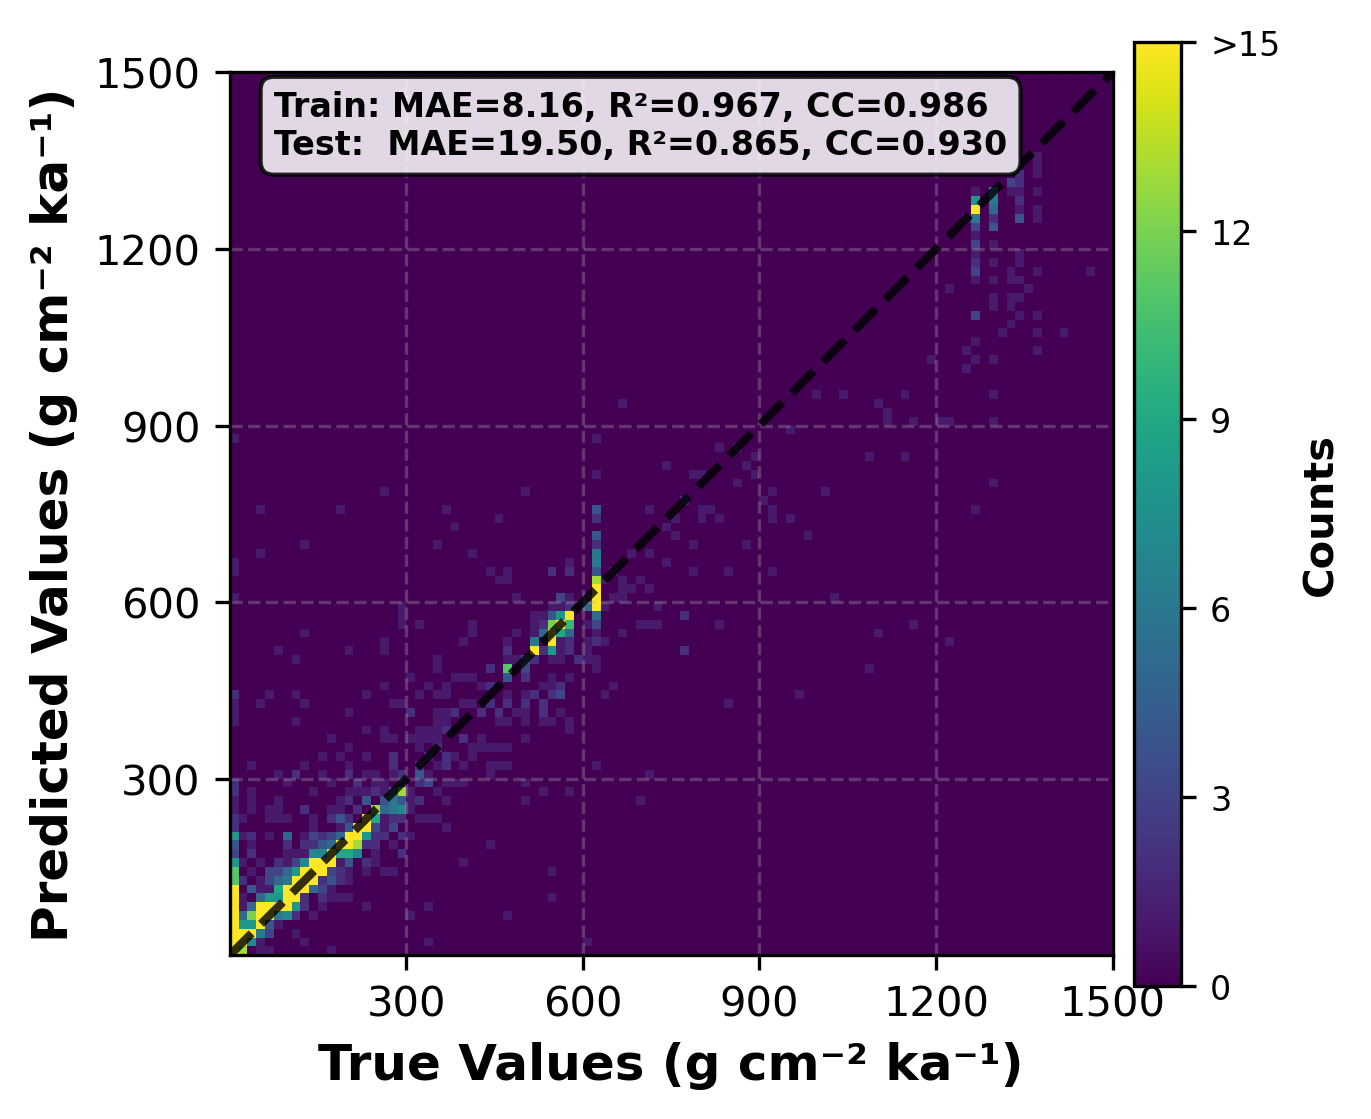

#### Prediction map (paper orientation + batlow)

random_forest: orientation fix = flipud (was south-up); map = prediction_map_MAR_entire_rf_n700.npy


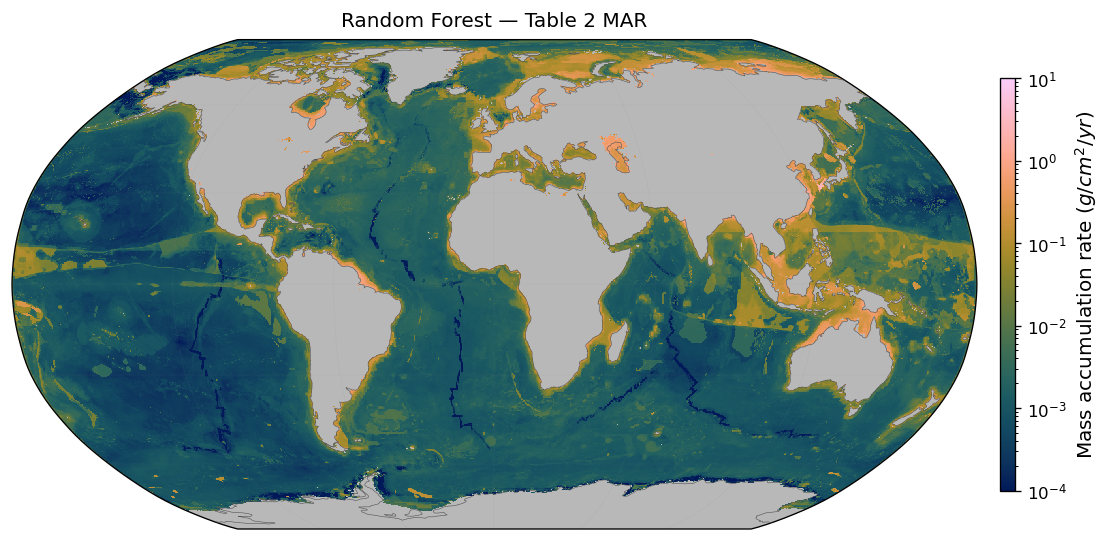

### XGBoost — Table 2

model,train_MAE,train_CC,test_MAE,test_CC,budget_Pg_yr
XGBoost,13.61,0.99,24.53,0.9,65.46


#### SI scatter (`scatter_entire_xgb`)

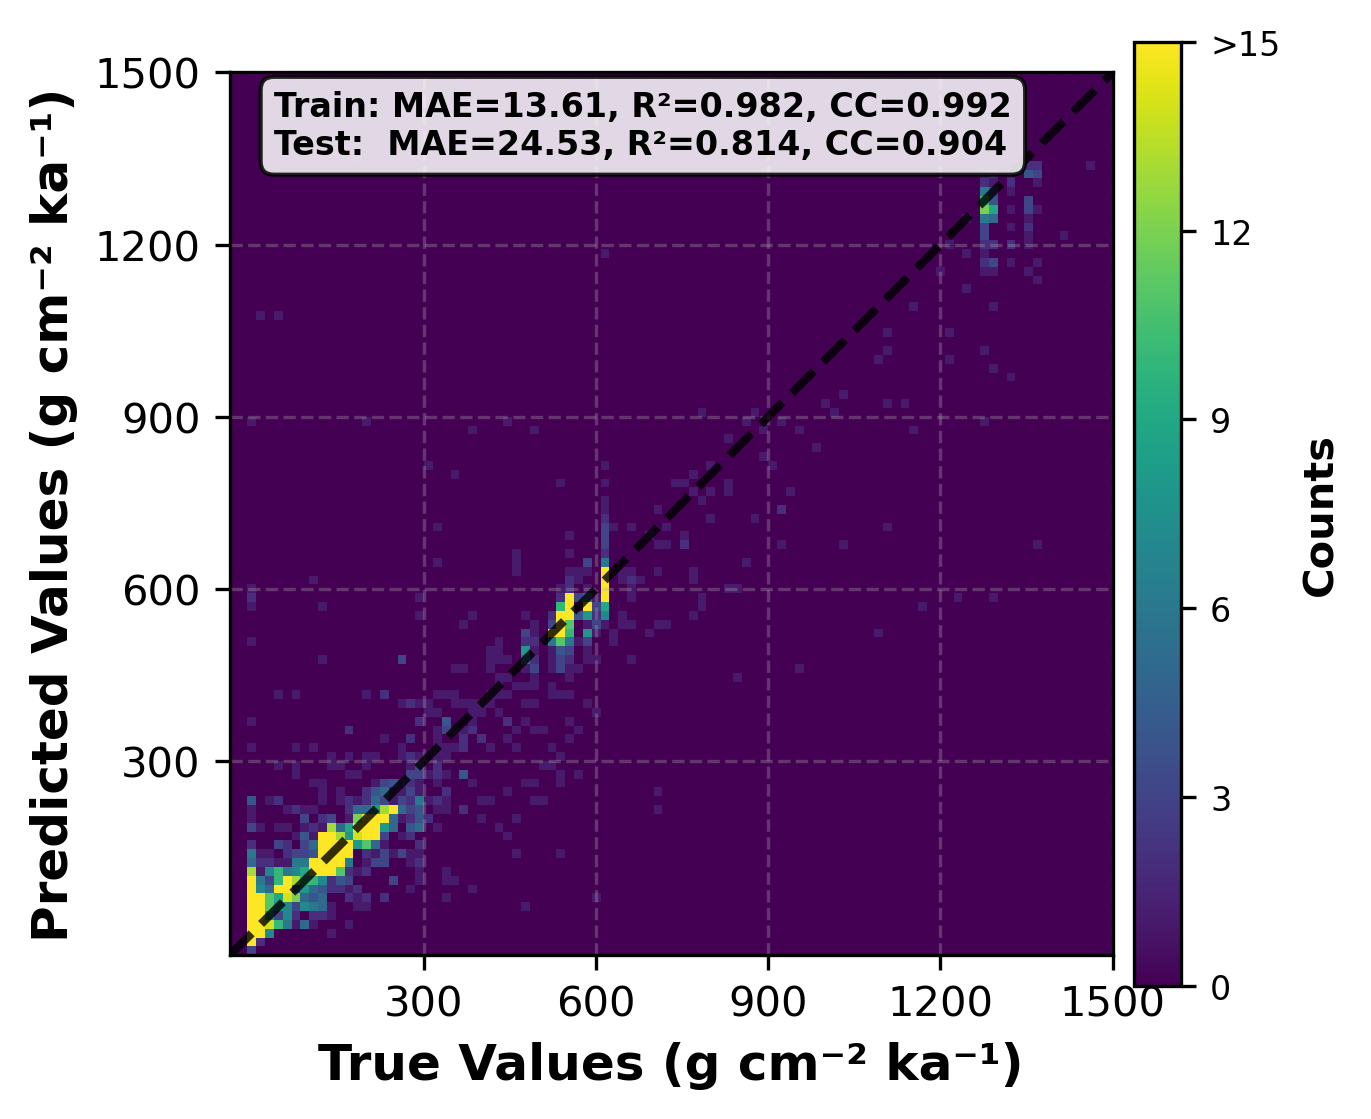

#### Prediction map (paper orientation + batlow)

xgboost: orientation fix = flipud (was south-up); map = prediction_map_MAR_entire_xgb_n1000.npy


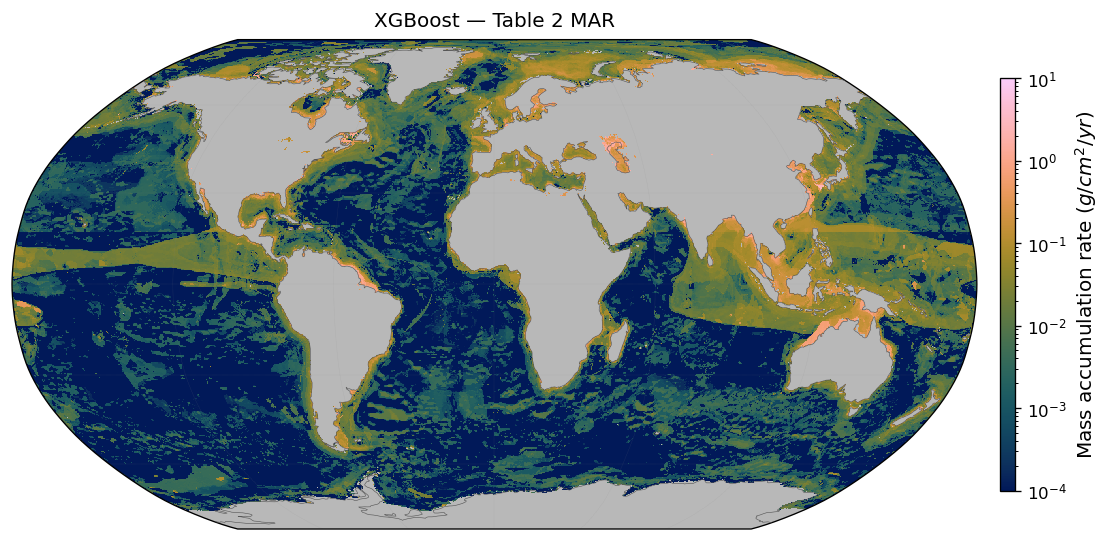

### CatBoost — Table 2

model,train_MAE,train_CC,test_MAE,test_CC,budget_Pg_yr
CatBoost,31.1,0.95,34.25,0.9,66.12


#### SI scatter (`scatter_entire_catb`)

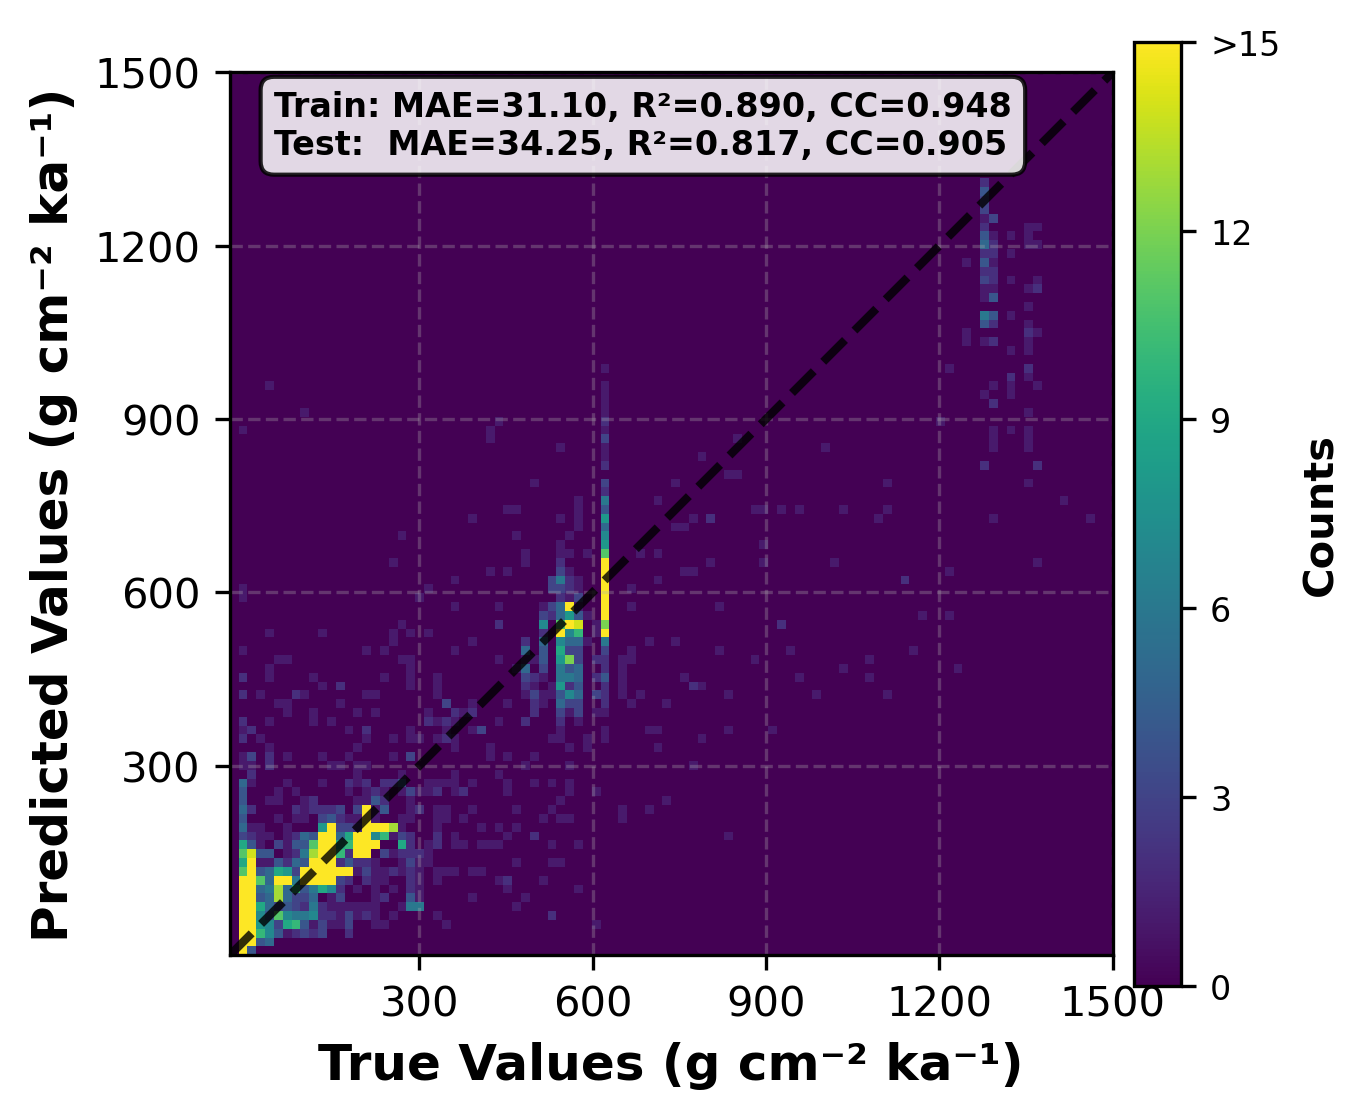

#### Prediction map (paper orientation + batlow)

catboost: orientation fix = flipud (was south-up); map = prediction_map_MAR_entire_catb_n1000.npy


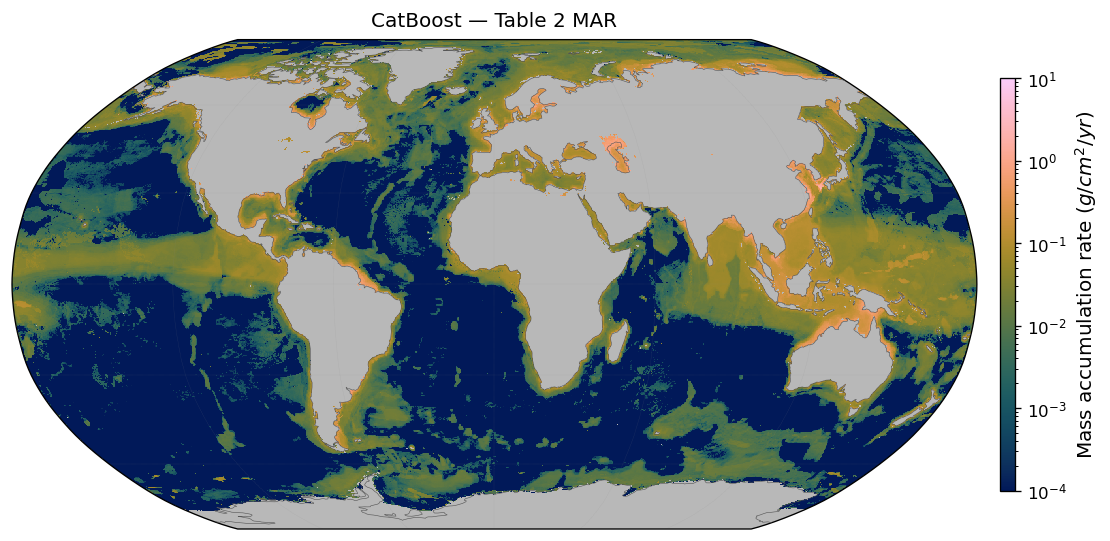

### KNN — Table 2

model,train_MAE,train_CC,test_MAE,test_CC,budget_Pg_yr
KNN,19.09,0.89,19.93,0.92,50.6


#### SI scatter (`scatter_entire_knn`)

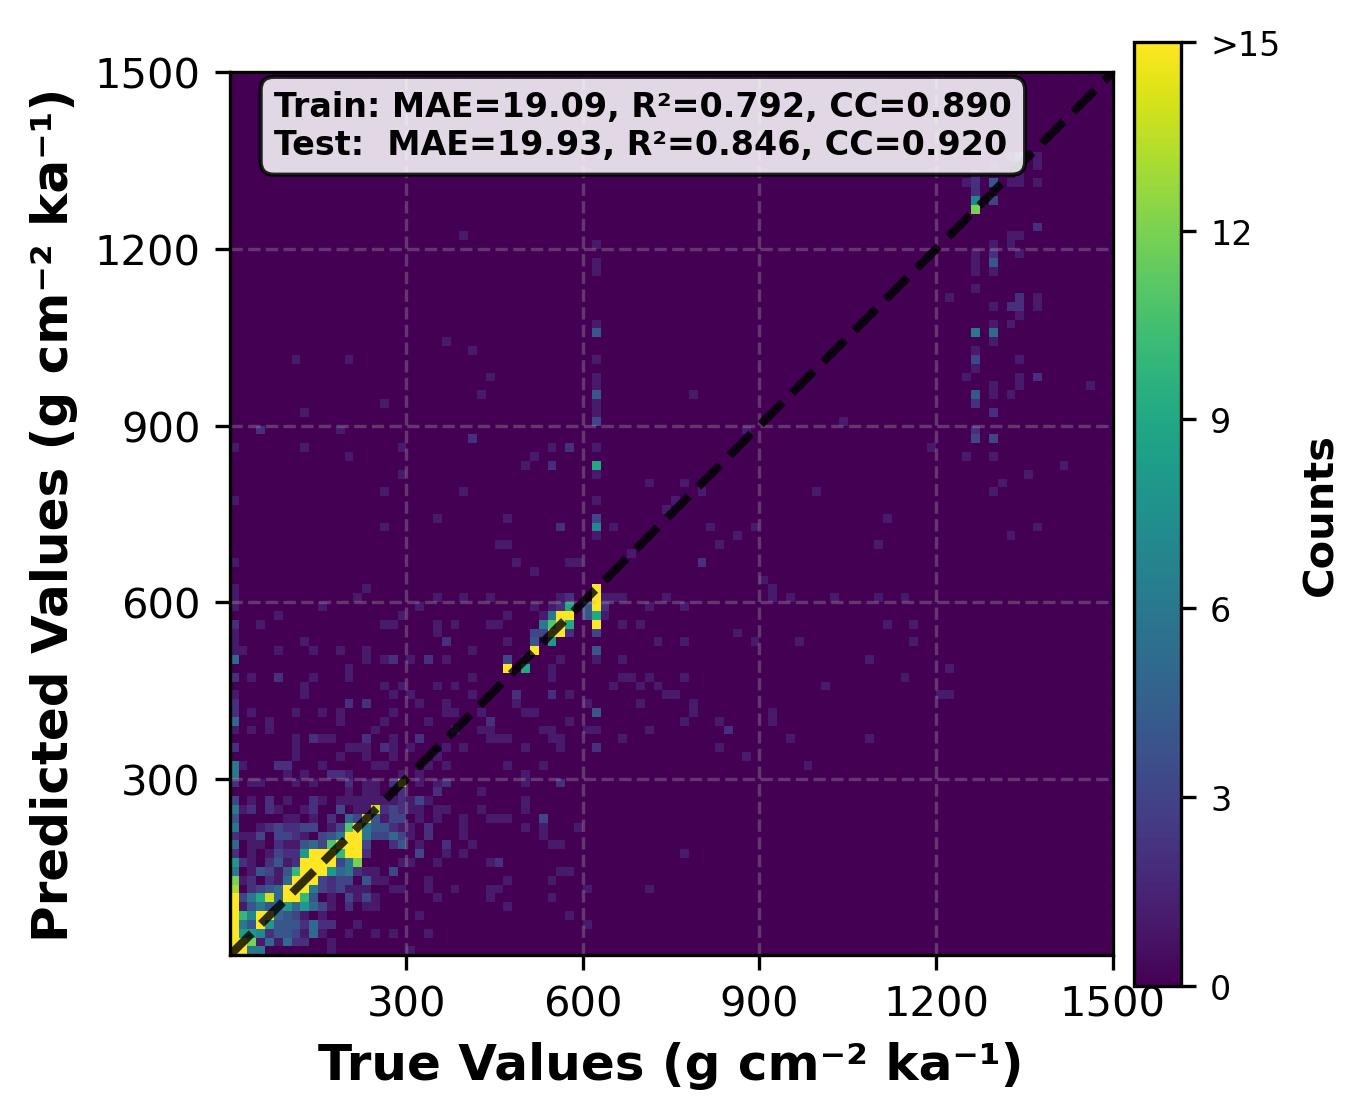

#### Prediction map (paper orientation + batlow)

knn: orientation fix = flipud (was south-up); map = prediction_map_MAR_entire_knn_k6.npy


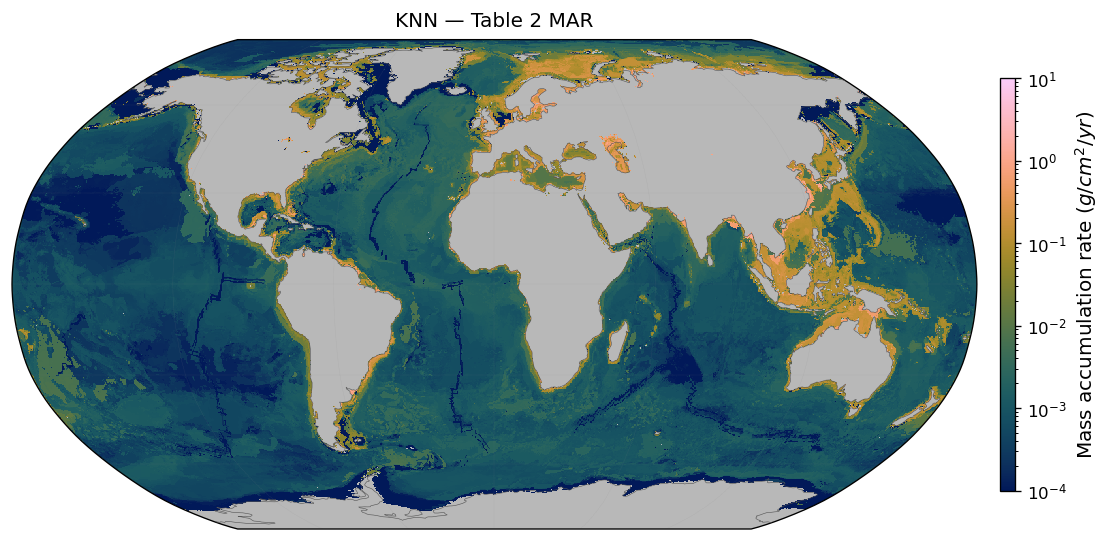

### TabPFN — Table 2

model,train_MAE,train_CC,test_MAE,test_CC,budget_Pg_yr
TabPFN,15.28,0.91,17.27,0.93,40.39


#### SI scatter (`scatter_entire_tabpfn`)

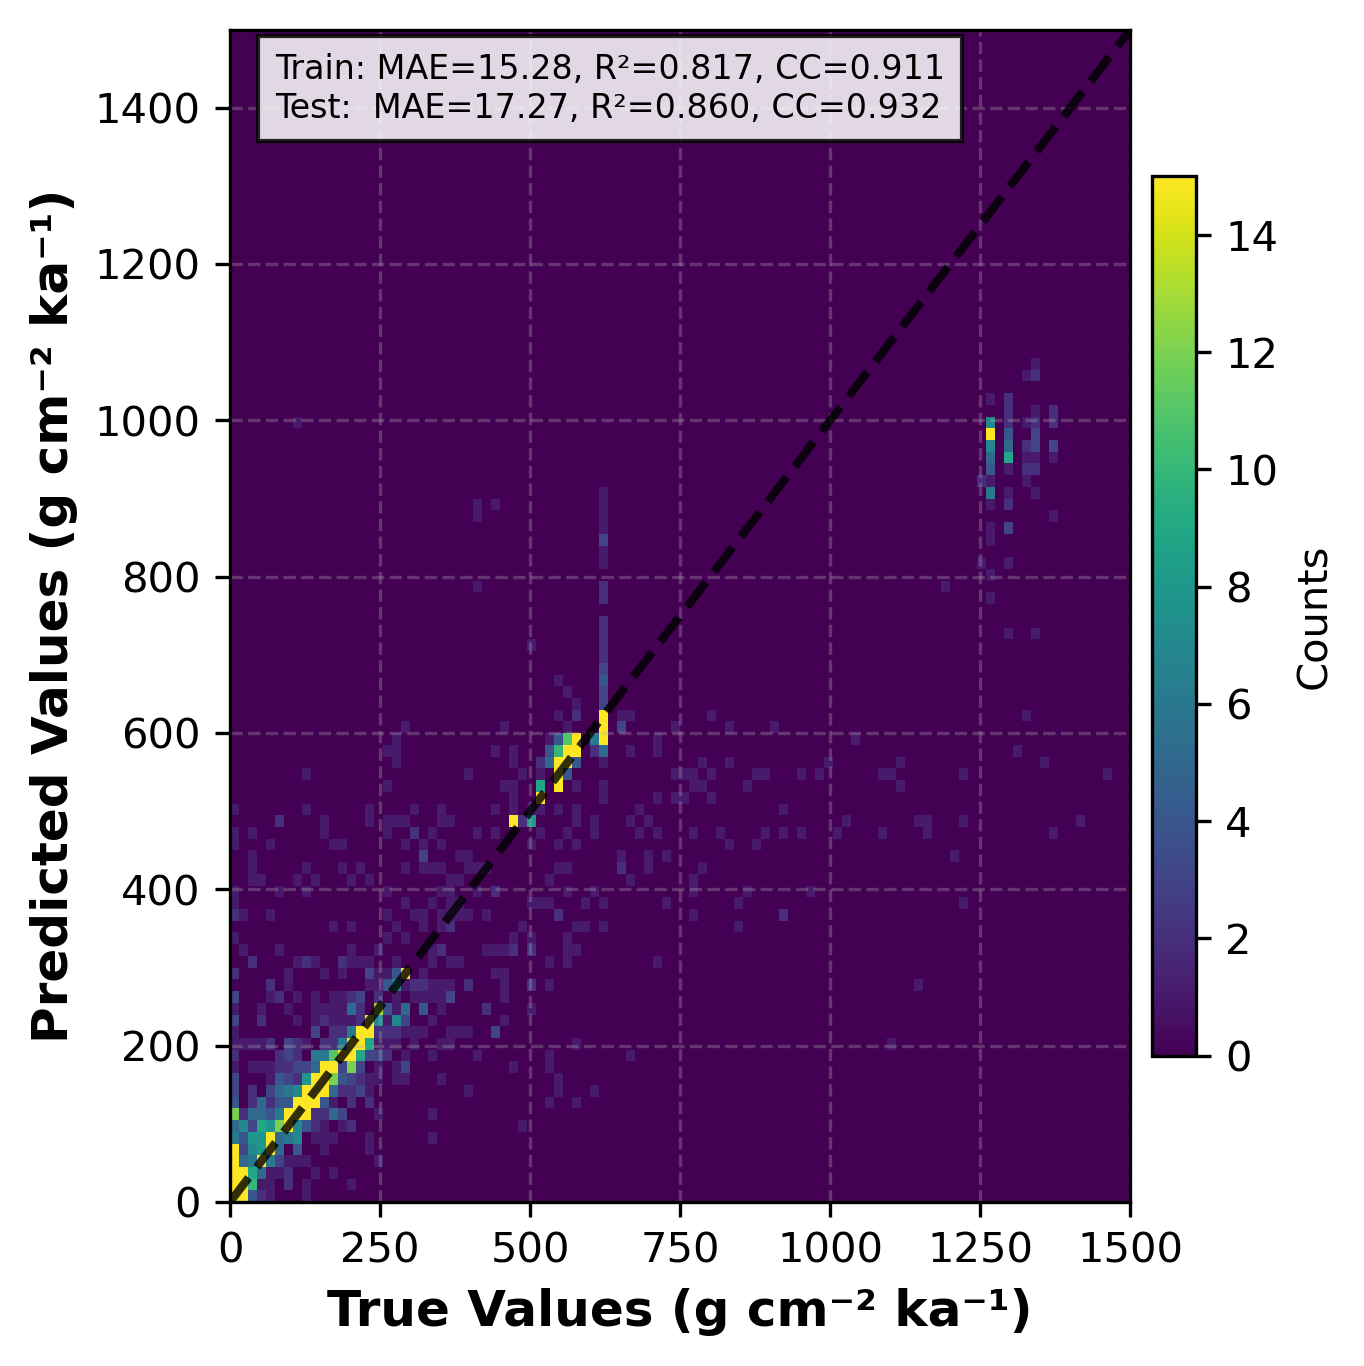

#### Prediction map (paper orientation + batlow)

tabpfn: orientation fix = as stored (north-up); map = prediction_map_MAR_entire_tabpfn_nomask.npy


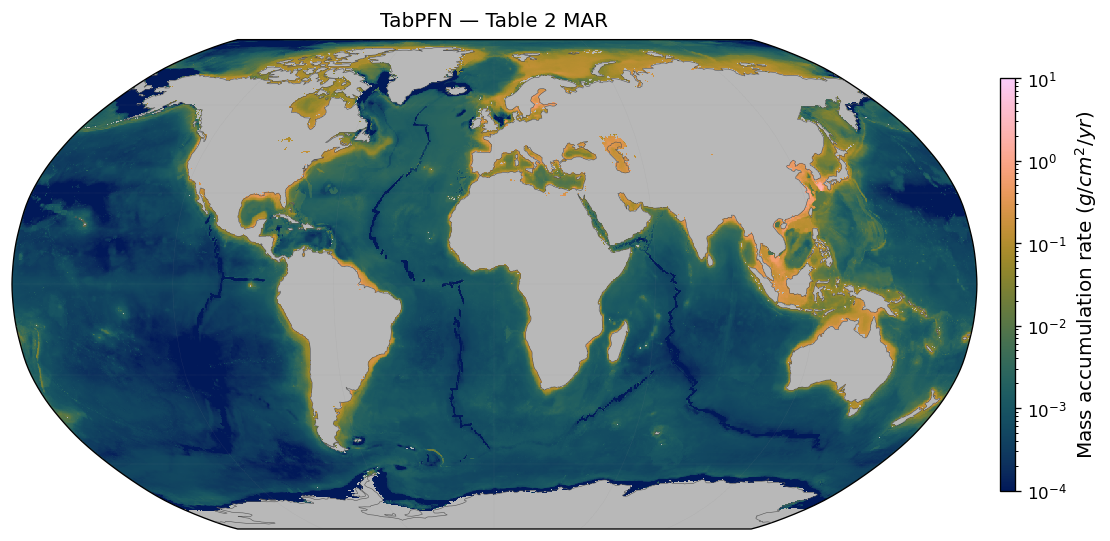

### FFNN — Table 2

model,train_MAE,train_CC,test_MAE,test_CC,budget_Pg_yr
FFNN,15.02,0.95,20.18,0.91,34.82


#### SI scatter (`scatter_entire_nn`)

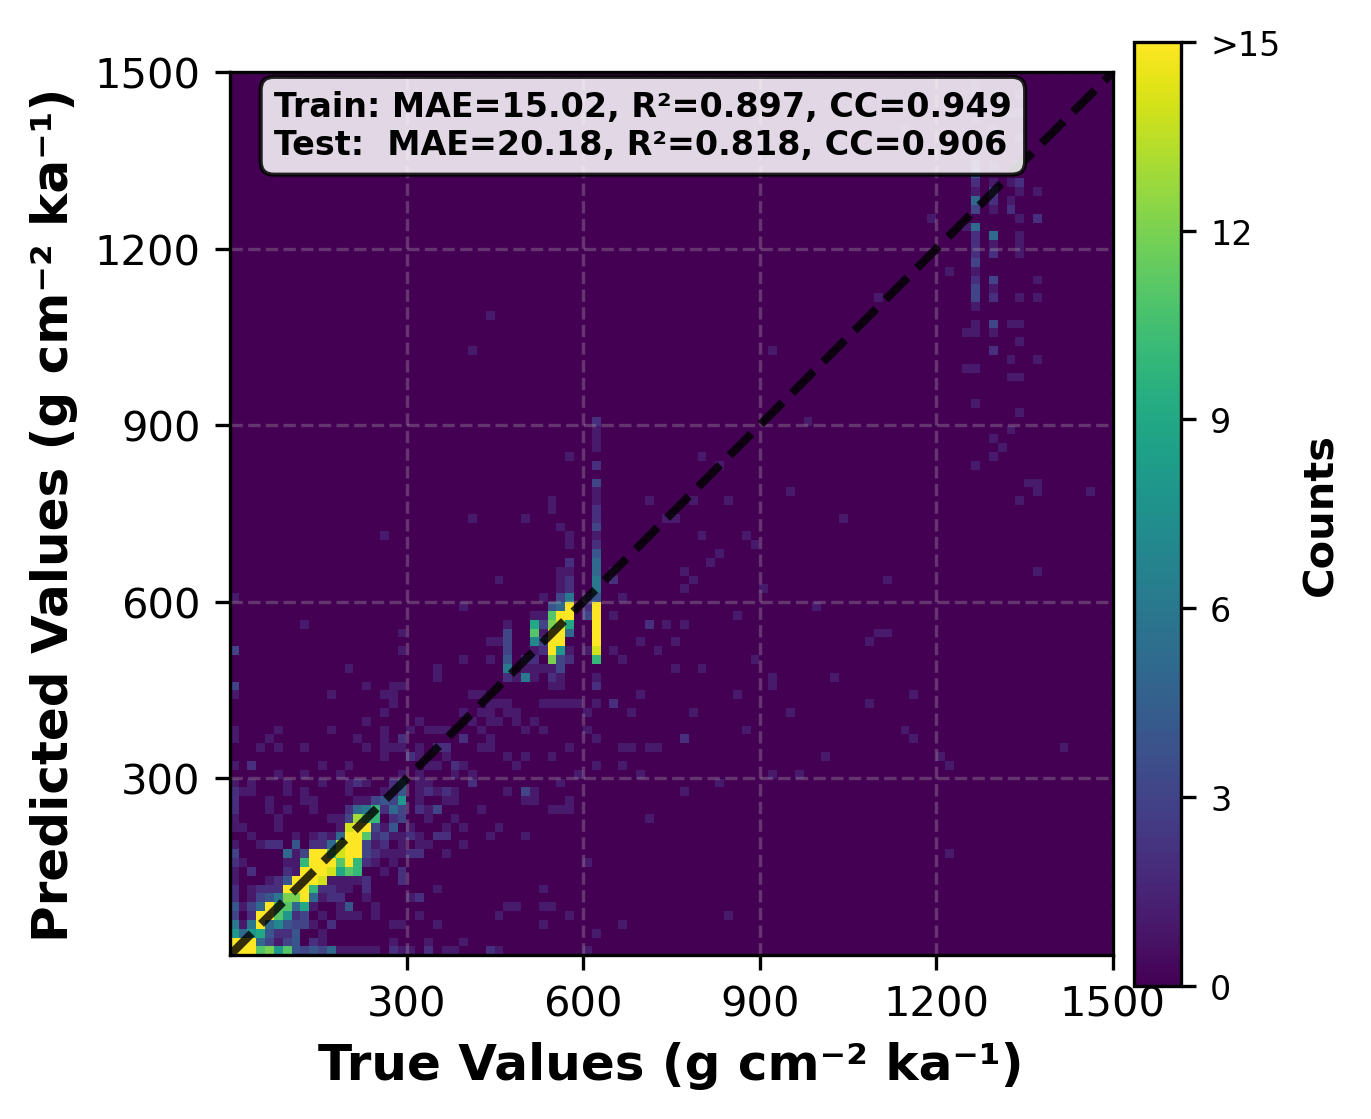

#### Prediction map (paper orientation + batlow)

ffnn: orientation fix = flipud (was south-up); map = prediction_map_SedRate_entire_supervised_nomask_[128, 128, 128].npy


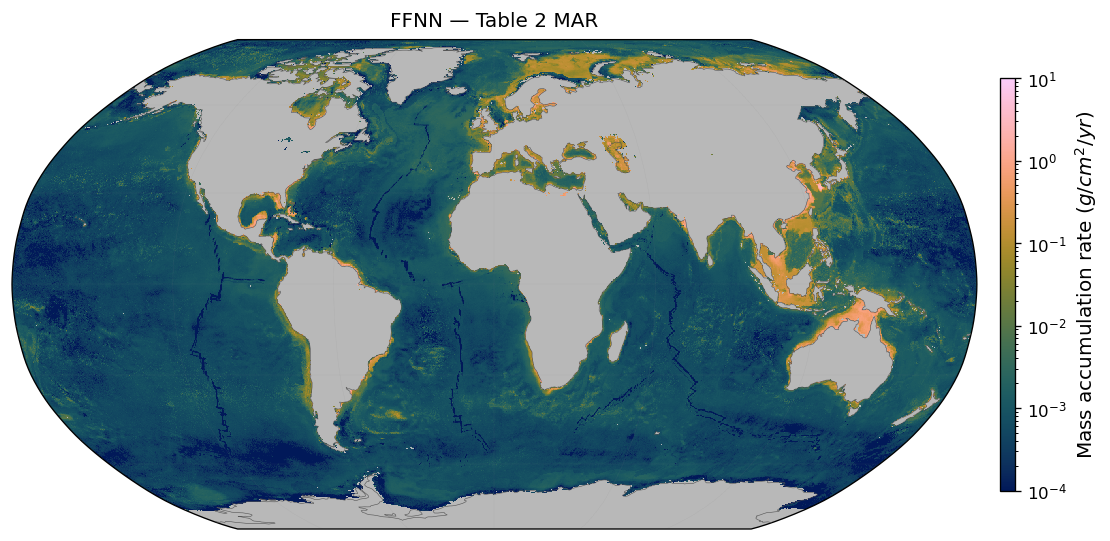

### MTL — Table 2

model,train_MAE,train_CC,test_MAE,test_CC,budget_Pg_yr
MTL,14.21,0.91,18.9,0.92,28.9


#### SI scatter (`scatter_entire_mtl`)

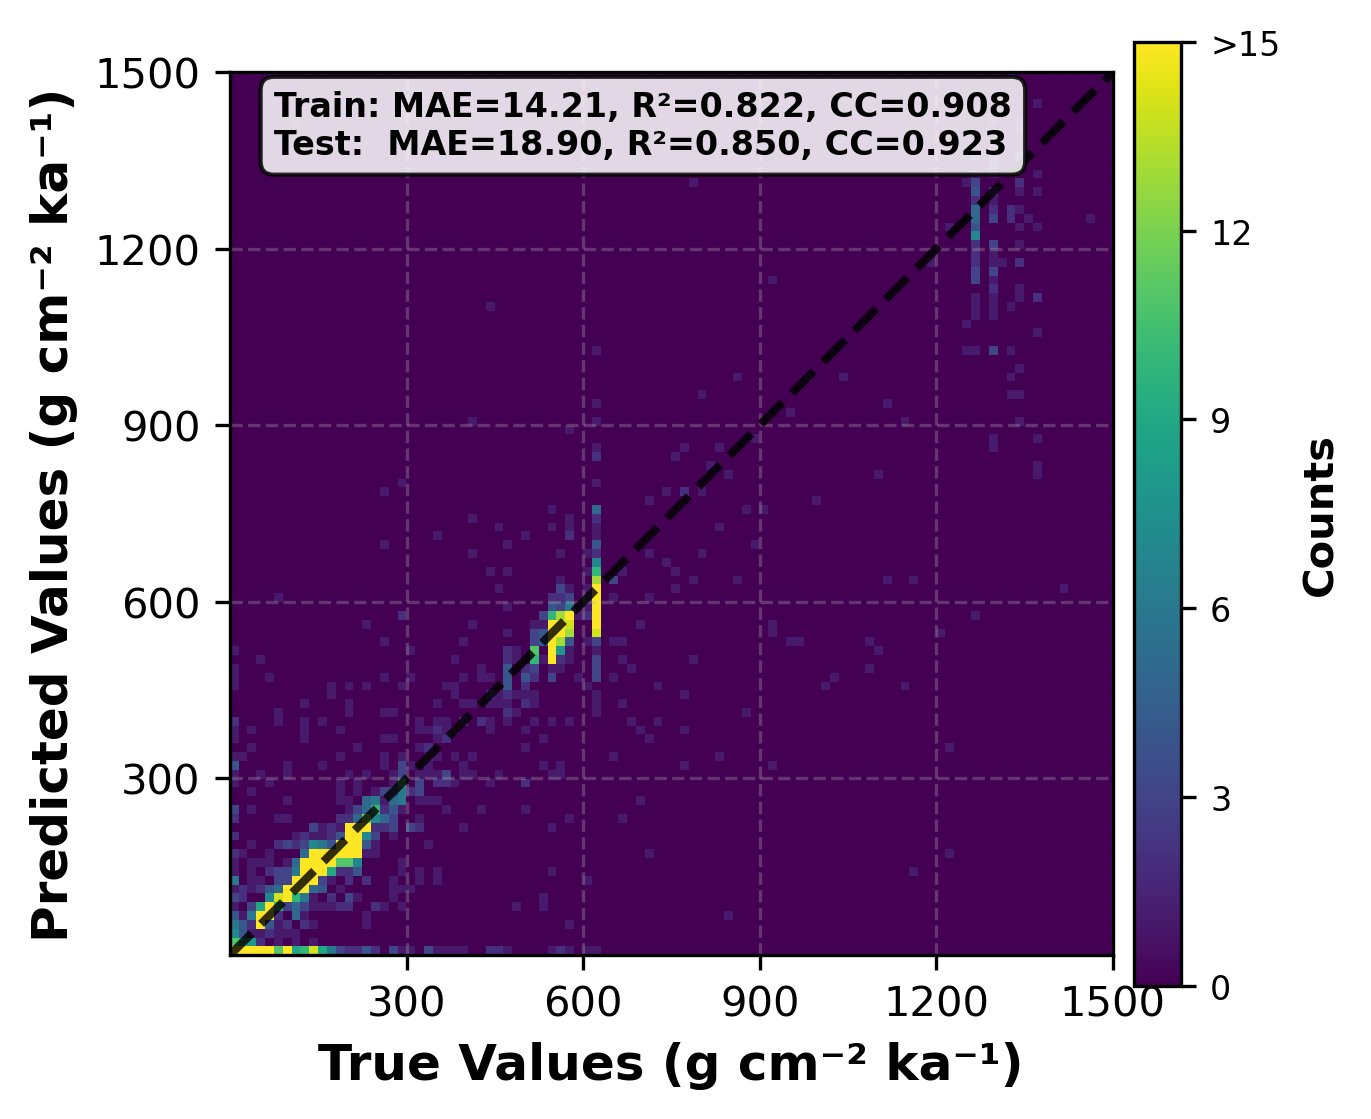

#### Prediction map (paper orientation + batlow)

mtl: orientation fix = as stored (north-up); map = prediction_map_MAR_entire_MTL_n_nomask_47.npy


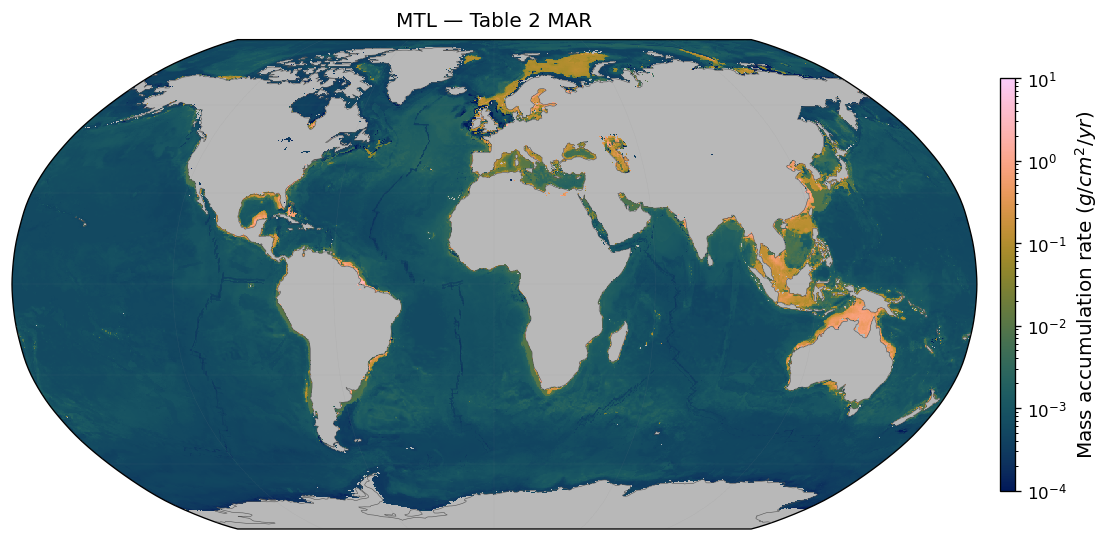

### FFNN + attention — Table 2

model,train_MAE,train_CC,test_MAE,test_CC,budget_Pg_yr
FFNN + attention,17.35,0.9,20.5,0.91,33.38


#### SI scatter (`scatter_entire_nn_attention`)

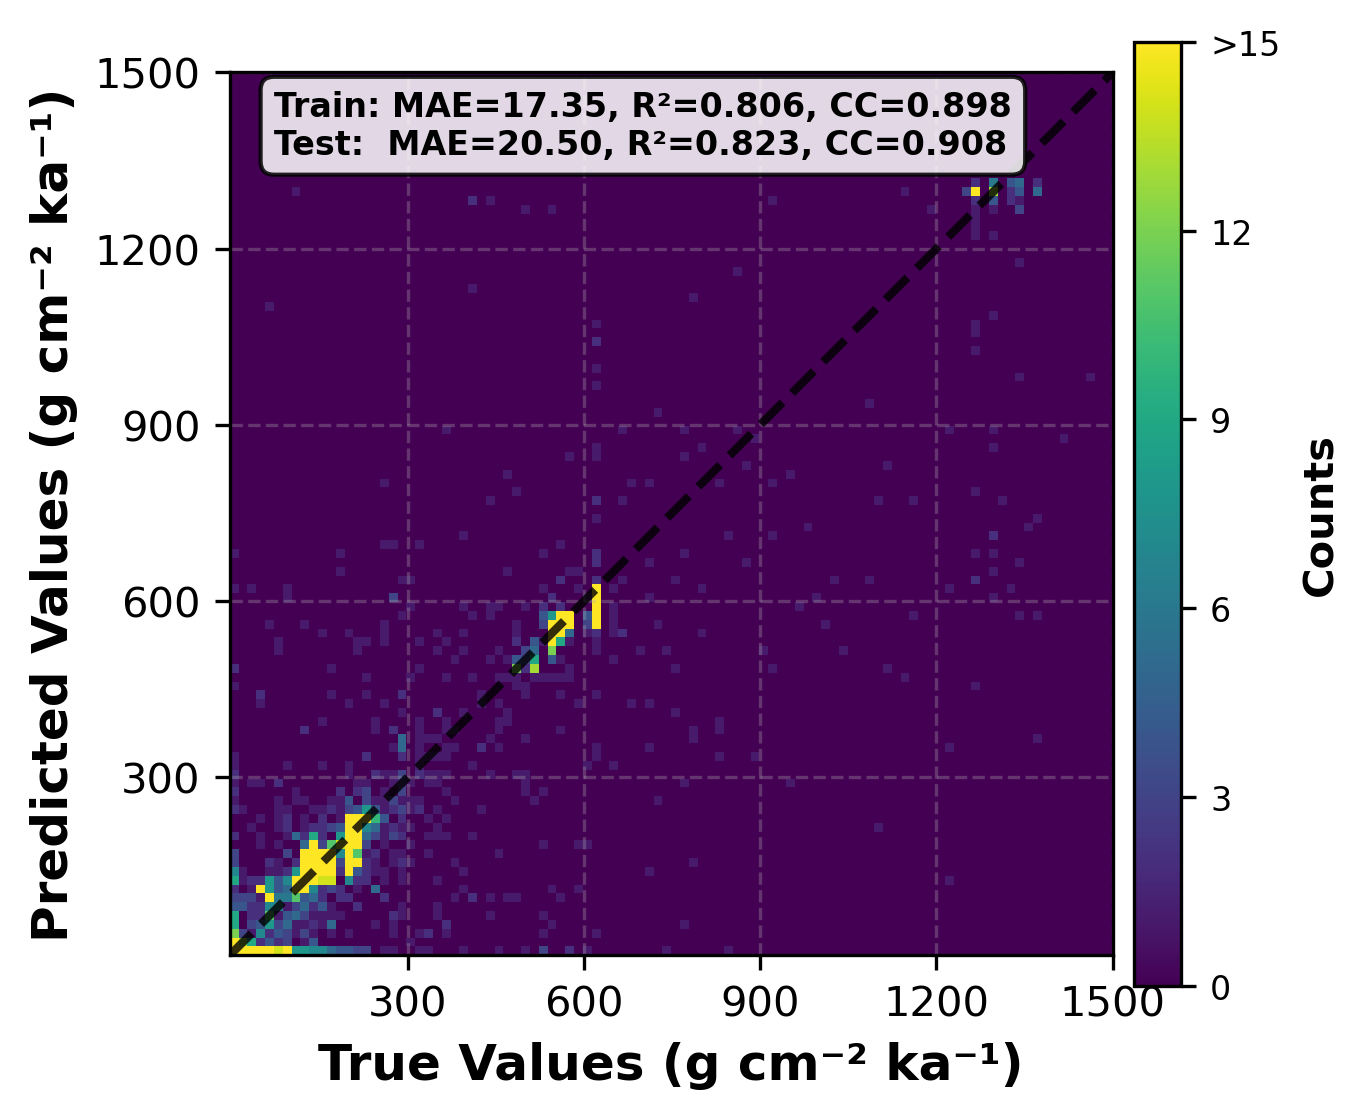

#### Prediction map (paper orientation + batlow)

ffnn_attention: orientation fix = flipud (was south-up); map = prediction_map_SedRate_entire_supervised_attention_attn_d256_h8_l3_ff2_do0.2.npy


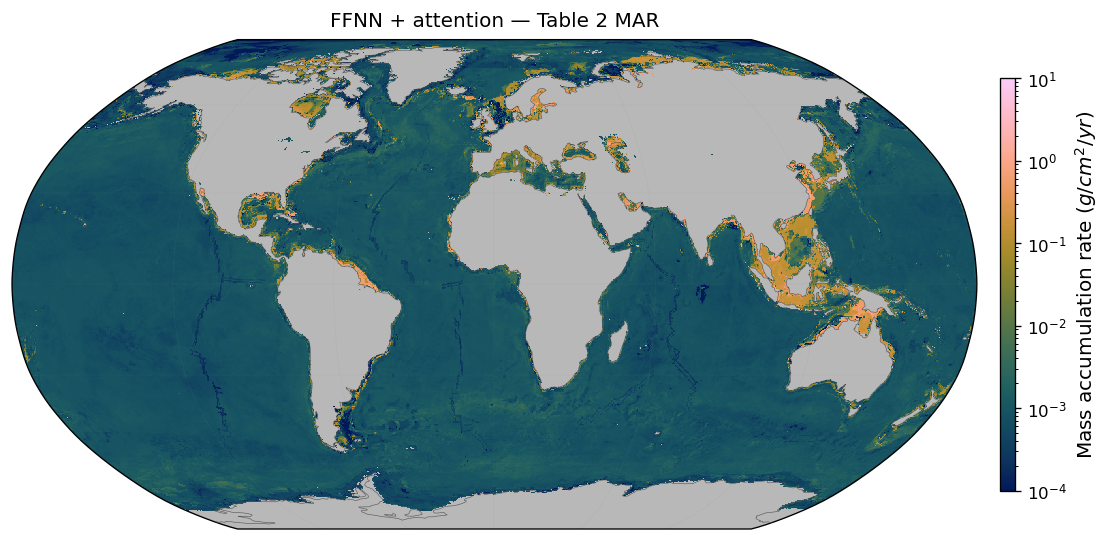

### MTL + attention — Table 2

model,train_MAE,train_CC,test_MAE,test_CC,budget_Pg_yr
MTL + attention,16.57,0.9,20.29,0.91,36.77


#### SI scatter (`scatter_entire_mtl_attention`)

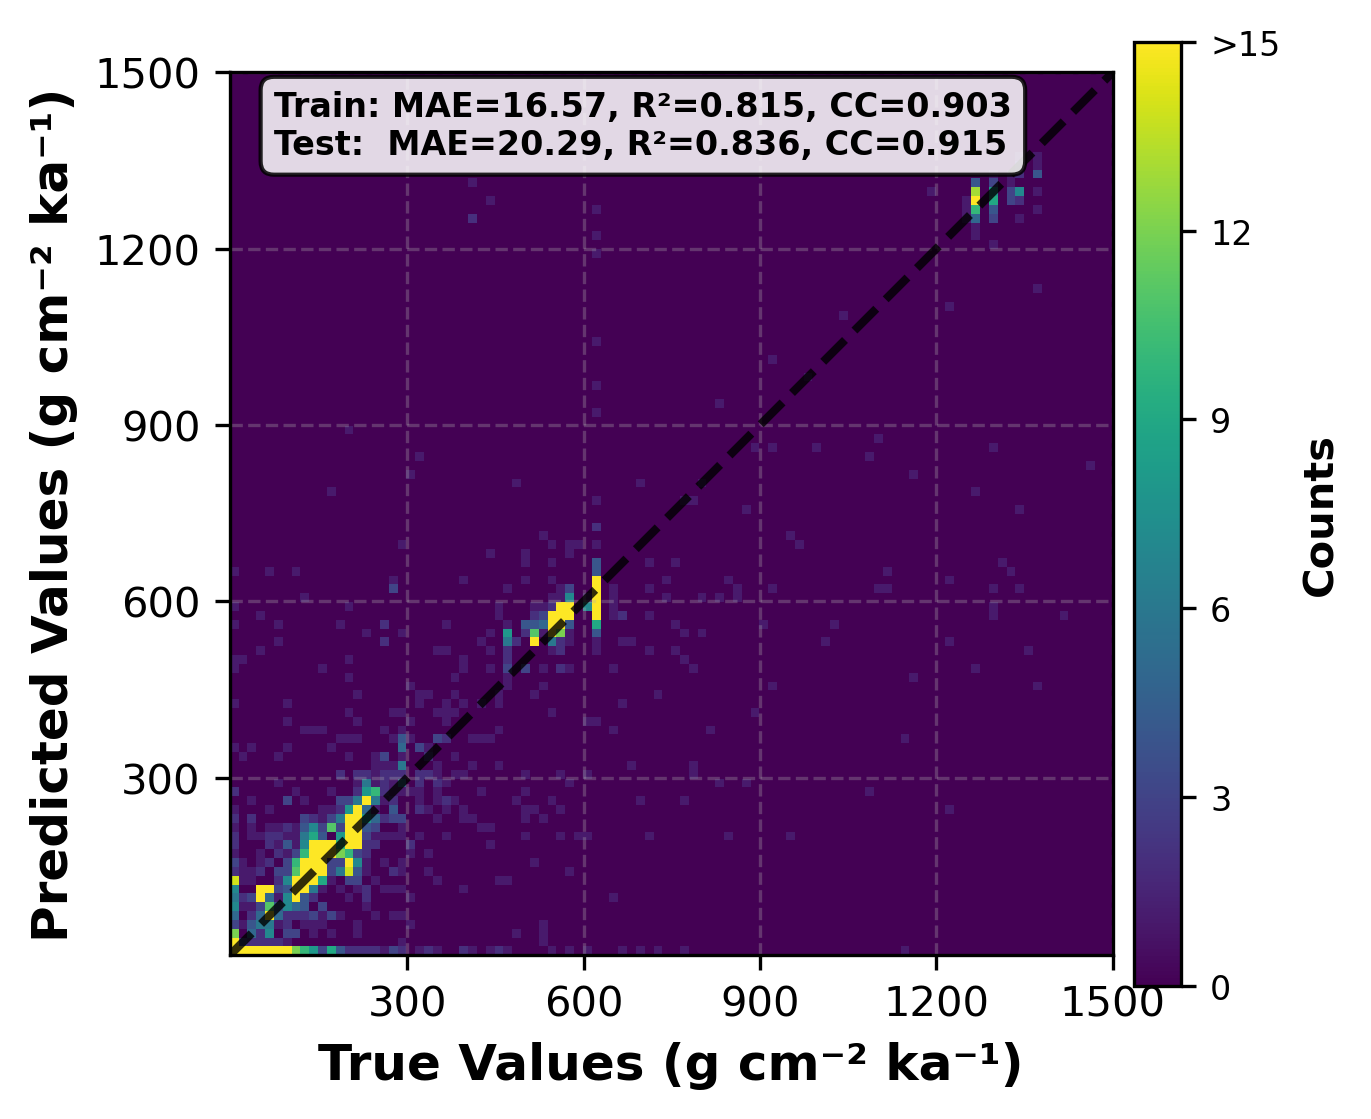

#### Prediction map (paper orientation + batlow)

mtl_attention: orientation fix = as stored (north-up); map = prediction_map_MAR_entire_MTL_n_attention_attn_d128_h8_l2_ff2_do0.2.npy


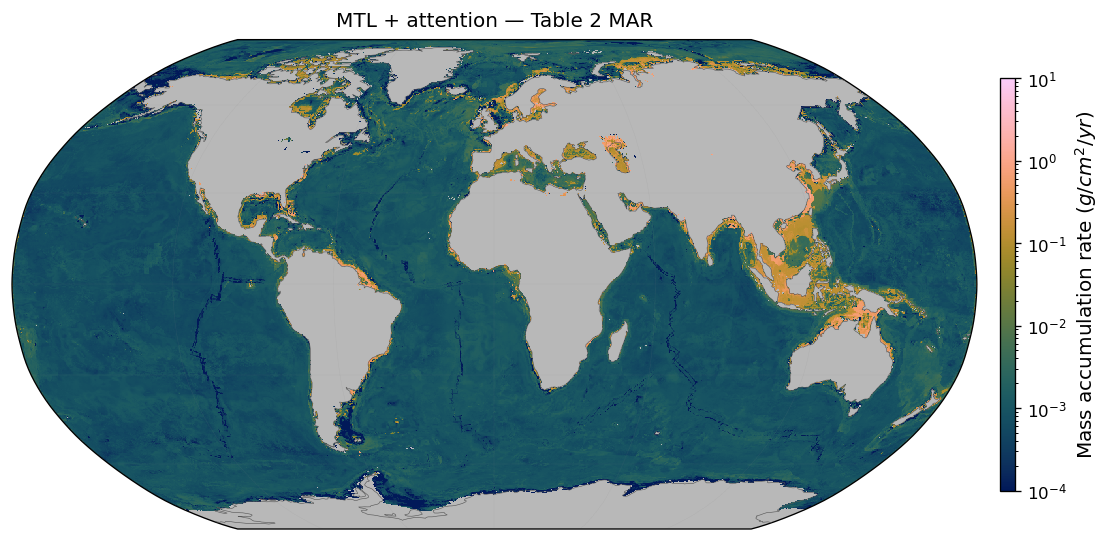

In [3]:
model_order = [
    "random_forest",
    "xgboost",
    "catboost",
    "knn",
    "tabpfn",
    "ffnn",
    "mtl",
    "ffnn_attention",
    "mtl_attention",
]
show_paper_models(model_order, project_root=project_root)


## Optional: re-score deltas vs Table 2


In [4]:
repro_csv = OUT / "table2_reproduction_metrics.csv"
if repro_csv.exists():
    repro = pd.read_csv(repro_csv)
    cols = [c for c in ["model", "test_mae", "table2_test_mae", "delta_test_mae", "test_cc", "table2_test_cc"] if c in repro.columns]
    display(repro[cols])
else:
    print("No re-score CSV yet.")


model,test_mae,table2_test_mae,delta_test_mae,test_cc,table2_test_cc
random_forest,19.495881,19.50,-0.004119,0.930080,0.93
xgboost,24.530809,24.53,0.000809,0.903835,0.90
catboost,34.251667,34.25,0.001667,0.904783,0.90
knn,19.928349,19.93,-0.001651,0.919714,0.92
tabpfn,17.270000,17.27,0.000000,0.930000,0.93
ffnn,21.706958,20.18,1.526958,0.905454,0.91
mtl,19.967847,18.90,1.067847,0.906678,0.92
ffnn_attention,20.495600,20.50,-0.004400,0.907906,0.91
mtl_attention,20.288063,20.29,-0.001937,0.914674,0.91
